# 3 · Co-current and counter-current plug flow

Both sides are in plug flow (a sweepless hollow-fibre module). The permeate starts with zero flow
at its closed end, where its composition equals the local cross-flow value.

* **Co-current**: the permeate flows with the feed, an initial-value problem in $L$.
* **Counter-current**: the permeate flows against the feed and leaves at the feed end, a
  two-point boundary-value problem. It is solved by **shooting from the closed (retentate) end**:
  guess the retentate composition, integrate back to the feed end, and correct the guess until the
  feed composition is recovered. In rare extreme cases (very selective membranes at high stage
  cut) the fast gas is stripped below double precision; the solver then switches to the
  analytical stripped limit.

Both models are checked in `tests/`: against the cross-flow limit as θ → 0, and against an
independent discretised counter-current model.

In [1]:
\
# --- Find the toolkit (works on your own computer and in Google Colab) ---
import sys, os, glob, pathlib

def _find_toolkit():
    here = pathlib.Path.cwd()
    for p in [here, *here.parents]:                       # running from inside the folder
        if (p / "gasmem" / "__init__.py").exists():
            return p
    for pat in ["/content/*/gasmem/__init__.py",           # Colab: zip unzipped in /content
                "/content/drive/MyDrive/gasmem/__init__.py",
                "/content/drive/MyDrive/*/gasmem/__init__.py",
                "/content/drive/MyDrive/*/*/gasmem/__init__.py",
                "/content/drive/MyDrive/*/*/*/gasmem/__init__.py"]:
        hits = sorted(glob.glob(pat))
        if hits:
            return pathlib.Path(hits[0]).parents[1]
    return None

TOOLKIT = _find_toolkit()
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if TOOLKIT is None and IN_COLAB:
    print("Looking for the toolkit in your Google Drive (approve the access request)...")
    from google.colab import drive
    drive.mount("/content/drive")
    TOOLKIT = _find_toolkit()
    if TOOLKIT is None:
        print("Not found in Drive. Choose gas-membrane-stagecut-toolkit.zip to upload:")
        import zipfile
        from google.colab import files
        for name in files.upload():
            zipfile.ZipFile(name).extractall("/content")
        TOOLKIT = _find_toolkit()
if TOOLKIT is None:
    raise FileNotFoundError("Could not find the 'gasmem' folder. Open this notebook from inside "
                            "the unzipped gas-membrane-stagecut-toolkit folder.")
sys.path.insert(0, str(TOOLKIT))
os.chdir(TOOLKIT / "notebooks")
print("Using toolkit at", TOOLKIT)
# ---------------------------------------------------------------------------

import numpy as np, pandas as pd, matplotlib.pyplot as plt
import ipywidgets as w
from IPython.display import display, Markdown
from gasmem import *
from gasmem.plotting import (plot_stage_cut_tradeoff, plot_purity_recovery, plot_profiles,
                             bar_breakdown, COLORS, MARKERS)
pd.set_option("display.precision", 4)

Using toolkit at /home/claude/gas-membrane-stagecut-toolkit


## All four flow patterns over the full range of stage cut

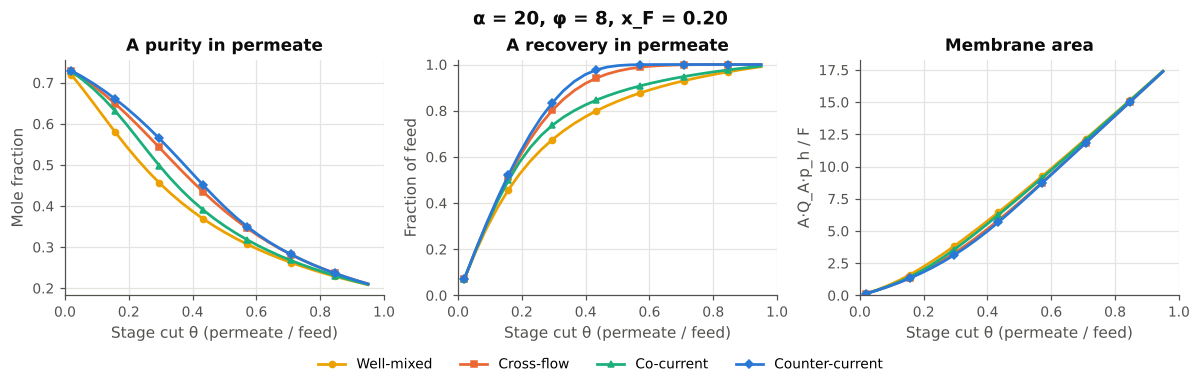

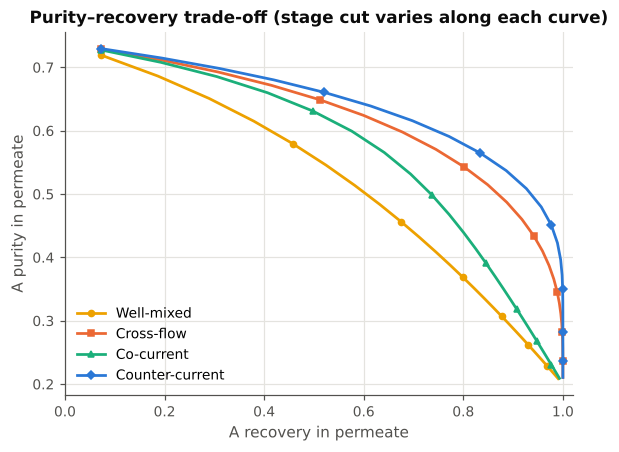

In [2]:
df = binary_sweep(alpha=20, phi=8, x_feed=0.2, thetas=np.linspace(0.02, 0.95, 28))
plot_stage_cut_tradeoff(df, "A", "area_dimless", area_label="A·Q_A·p_h / F",
                        title="α = 20, φ = 8, x_F = 0.20"); plt.show()
plot_purity_recovery(df, "A"); plt.show()

Counter-current is best because the leanest feed (near the retentate end) faces the leanest
permeate, and the richest feed faces the permeate that is about to leave. The local driving force
stays high along the whole module.

In **co-current** flow the bulk permeate is carried along with the feed. Once the feed-side
fast-gas fraction falls to about $y/\varphi$ there is no driving force left for the fast gas, and
the feed cannot be stripped further. This **pinch** is visible in the retentate below.

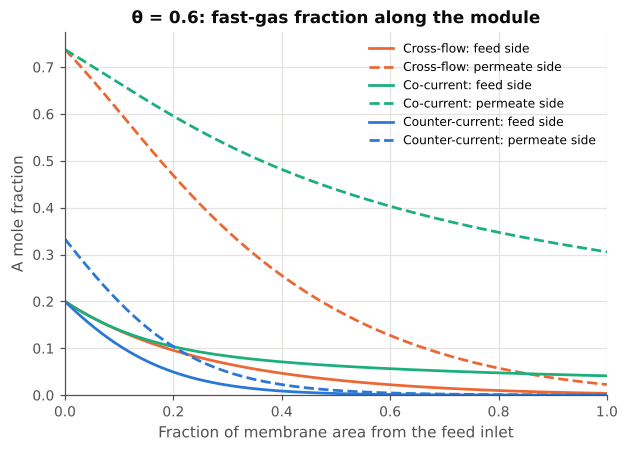

,permeate y_A,retentate x_A,"area (m2, F = 1 mol/s)"
Cross-flow,0.3308,3.8484e-03,351.3049
Co-current,0.3058,4.1262e-02,363.4436
Counter-current,0.3333,7.2938e-05,350.0800


In [3]:
m = Membrane.binary(20)
res = {p: solve_stage(m, [0.2, 0.8], 0.6, 8.0, 1.0, p, profile=True)
       for p in ["cross_flow", "cocurrent", "countercurrent"]}
plot_profiles(res, "A", title="θ = 0.6: fast-gas fraction along the module"); plt.show()
pd.DataFrame({LABELS[p]: {"permeate y_A": r.y_perm[0], "retentate x_A": r.x_ret[0],
                          "area (m2, F = 1 mol/s)": r.area} for p, r in res.items()}).T

## Interactive comparison

In [4]:
def explore(alpha=20.0, phi=8.0, x_feed=0.2, theta=0.5):
    df = binary_sweep(alpha, phi, x_feed, np.linspace(0.03, 0.93, 20))
    plot_stage_cut_tradeoff(df, "A", "area_dimless", theta_now=theta, area_label="A·Q_A·p_h / F")
    plt.show()
    pts = df.loc[(df["theta"] - theta).abs().groupby(df["pattern"]).idxmin()]
    display(pts[["pattern", "theta", "purity", "recovery", "retentate_slow_purity", "area_dimless"]]
            .set_index("pattern"))

w.interact(explore,
           alpha=w.FloatSlider(value=20, min=1.5, max=100, step=0.5, continuous_update=False, description="α"),
           phi=w.FloatSlider(value=8, min=1.2, max=100, step=0.2, continuous_update=False, description="φ"),
           x_feed=w.FloatSlider(value=0.2, min=0.02, max=0.9, step=0.01, continuous_update=False, description="x feed"),
           theta=w.FloatSlider(value=0.5, min=0.03, max=0.93, step=0.01, continuous_update=False, description="θ"));

interactive(children=(FloatSlider(value=20.0, continuous_update=False, description='α', min=1.5, step=0.5), Fl…

**Things to try**

* Set φ ≫ α (selectivity limited): the four patterns move closer together.
* Set φ ≪ α (pressure-ratio limited): flow pattern matters most, and counter-current pulls ahead.
* Move θ towards 1: every pattern converges to the feed composition in the permeate, but the
  retentate purity differs a lot.